# 01 – Compreensão e avaliação da qualidade dos dados

Neste notebook eu carrego os dados brutos baixados pelo `src/ingestao.py`, entendo o que cada coluna representa e procuro os problemas de qualidade **que realmente aparecem** na base.

Aqui **não** corrijo nada: só identifico e meço. Os tratamentos ficam no notebook `02_limpeza_e_preparacao`.

Roteiro:
1. Carregar as bases e entender as colunas
2. Filtrar só os gatos
3. Avaliar a qualidade: ausentes, duplicados, tipos, formatos, categorias, valores inválidos, outliers
4. Resumo dos problemas encontrados

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# mostra mais colunas na tela, senão o pandas esconde algumas
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

## 1. Carregando os dados brutos

Leio tudo como texto (`dtype=str`) de propósito: assim vejo o dado exatamente como veio do portal, sem o pandas tentar converter nada sozinho.

In [2]:
# dtype=str: leio tudo como texto, pra ver o dado exatamente como veio do portal
entradas_raw = pd.read_csv("../data/raw/intakes.csv", dtype=str)
saidas_raw = pd.read_csv("../data/raw/outcomes.csv", dtype=str)

print("Entradas:", entradas_raw.shape)
print("Saídas:  ", saidas_raw.shape)

Entradas: (173812, 12)
Saídas:   (173775, 12)


In [3]:
# data do download e quantidade de linhas, gravados pelo script de ingestão
print(open("../data/raw/info_download.txt", encoding="utf-8").read())

data do download: 2026-10-06
intakes (wter-evkm): 173812 linhas | portal: 173812 | dados atualizados no portal em 2025-05-19
outcomes (9t4d-g238): 173775 linhas | portal: 173775 | dados atualizados no portal em 2025-05-19



### O que o portal diz sobre as bases

Além dos CSVs, o script de ingestão salvou os **metadados** de cada base, que vêm da API JSON do portal. Com eles confiro o período coberto, quando os dados foram atualizados pela última vez e se o portal descreve as colunas.

In [4]:
import json

# os metadados que o ingestao.py salvou: a "ficha" de cada base no portal
for nome in ["intakes", "outcomes"]:
    meta = json.load(open(f"../data/raw/metadados_{nome}.json", encoding="utf-8"))
    # quantas colunas têm descrição preenchida no portal (deu 0 nas duas)
    com_descricao = sum(bool(c.get("description")) for c in meta["columns"])
    print(meta["name"])
    # a data vem em segundos desde 1970, por isso o unit="s"
    print("  dados atualizados em:", pd.to_datetime(meta["rowsUpdatedAt"], unit="s").date())
    print("  colunas com descrição:", com_descricao, "de", len(meta["columns"]))

Austin Animal Center Intakes (10/01/2013 to 05/05/2025)
  dados atualizados em: 2025-05-19
  colunas com descrição: 0 de 12
Austin Animal Center Outcomes (10/01/2013 to 05/05/2025)
  dados atualizados em: 2025-05-19
  colunas com descrição: 0 de 12


**Achados:**
- As duas bases estão **congeladas**: o próprio título diz que cobrem de 01/10/2013 a 05/05/2025, e os dados não mudam desde maio de 2025. Isso vai explicar, mais adiante, os gatos que entraram e não têm saída registrada.
- **Nenhuma coluna tem descrição** no portal. O significado de cada uma (tabela abaixo) teve que ser deduzido por mim.

In [5]:
# primeiras linhas, pra ver a cara de cada base
entradas_raw.head()

,Animal ID,Name,DateTime,MonthYear,Found Location,Intake Type,Intake Condition,Animal Type,Sex upon Intake,Age upon Intake,Breed,Color
0,A521520,Nina,10/01/2013 07:51:00 AM,October 2013,Norht Ec in Austin (TX),Stray,Normal,Dog,Spayed Female,7 years,Border Terrier/Border Collie,White/Tan
1,A664235,NaN,10/01/2013 08:33:00 AM,October 2013,Abia in Austin (TX),Stray,Normal,Cat,Unknown,1 week,Domestic Shorthair Mix,Orange/White
2,A664236,NaN,10/01/2013 08:33:00 AM,October 2013,Abia in Austin (TX),Stray,Normal,Cat,Unknown,1 week,Domestic Shorthair Mix,Orange/White
3,A664237,NaN,10/01/2013 08:33:00 AM,October 2013,Abia in Austin (TX),Stray,Normal,Cat,Unknown,1 week,Domestic Shorthair Mix,Orange/White
4,A664233,Stevie,10/01/2013 08:53:00 AM,October 2013,7405 Springtime in Austin (TX),Stray,Injured,Dog,Intact Female,3 years,Pit Bull Mix,Blue/White


In [6]:
saidas_raw.head()

,Animal ID,Date of Birth,Name,DateTime,MonthYear,Outcome Type,Outcome Subtype,Animal Type,Sex upon Outcome,Age upon Outcome,Breed,Color
0,A668305,2012-12-01,NaN,2013-12-02T00:00:00-05:00,12-2013,Transfer,Partner,Other,Unknown,1 year,Turtle Mix,Brown/Yellow
1,A673335,2012-02-22,NaN,2014-02-22T00:00:00-05:00,02-2014,Euthanasia,Suffering,Other,Unknown,2 years,Raccoon,Black/Gray
2,A675999,2013-04-03,NaN,2014-04-07T00:00:00-05:00,04-2014,Transfer,Partner,Other,Unknown,1 year,Turtle Mix,Green
3,A679066,2014-04-16,NaN,2014-05-16T00:00:00-05:00,05-2014,NaN,NaN,Other,Unknown,4 weeks,Rabbit Sh,Brown
4,A680855,2014-05-25,NaN,2014-06-10T00:00:00-05:00,06-2014,Transfer,Partner,Bird,Unknown,2 weeks,Duck,Yellow/Black


### O que cada coluna representa

As duas bases se ligam pelo `Animal ID`. Cada linha de **Intakes** é uma entrada de um animal no abrigo e cada linha de **Outcomes** é uma saída. Como os metadados mostraram, o portal não descreve as colunas. A tabela abaixo foi montada por mim a partir dos nomes e dos valores observados.

| Coluna | Base | O que é | Relevante pro projeto? |
|---|---|---|---|
| `Animal ID` | ambas | identificador do animal (o mesmo animal pode aparecer mais de uma vez) | sim, chave pra juntar as bases |
| `Name` | ambas | nome do animal | sim, pergunta 3 (sem nome) |
| `DateTime` | ambas | data/hora da entrada ou da saída | sim, tempo no abrigo e sazonalidade |
| `MonthYear` | ambas | mês/ano do evento (repete a informação do `DateTime`) | não, é redundante |
| `Found Location` | entradas | endereço onde o animal foi encontrado | não para as perguntas atuais |
| `Intake Type` | entradas | tipo de entrada (perdido, entregue pelo dono...) | sim, pergunta 5 |
| `Intake Condition` | entradas | condição na entrada (normal, ferido, doente...) | sim, pergunta 5 |
| `Animal Type` | ambas | espécie (Cat, Dog, Other...) | usado só para filtrar gatos |
| `Sex upon Intake` / `Sex upon Outcome` | cada uma | sexo + castração juntos | sim, perguntas 4 |
| `Age upon Intake` / `Age upon Outcome` | cada uma | idade em texto ("2 years") | sim, pergunta 2 |
| `Breed` | ambas | raça | sim, característica do gato |
| `Color` | ambas | cor/padrão da pelagem | sim, pergunta 1 |
| `Date of Birth` | saídas | data de nascimento | usada só para checar a idade |
| `Outcome Type` | saídas | desfecho (adoção, transferência...) | sim, é o resultado que quero estudar |
| `Outcome Subtype` | saídas | detalhe do desfecho | complementar |

## 2. Filtrando só os gatos

As bases têm todos os animais do abrigo. O projeto é sobre gatos, então olho a coluna `Animal Type`.

In [7]:
# o abrigo recebe vários animais; quantos de cada tipo?
entradas_raw["Animal Type"].value_counts()

Animal Type
Dog          94608
Cat          69324
Other         8968
Bird           878
Livestock       34
Name: count, dtype: int64

In [8]:
# daqui pra frente só gatos (.copy() pra não mexer na tabela original)
entradas = entradas_raw[entradas_raw["Animal Type"] == "Cat"].copy()
saidas = saidas_raw[saidas_raw["Animal Type"] == "Cat"].copy()

print("Entradas de gatos:", len(entradas))
print("Saídas de gatos:  ", len(saidas))

Entradas de gatos: 69324
Saídas de gatos:   69399


## 3. Avaliação da qualidade

### 3.1 Valores ausentes

In [9]:
# quantos vazios tem em cada coluna, nas duas bases lado a lado
pd.DataFrame({
    "ausentes_entradas": entradas.isna().sum(),
    "ausentes_saidas": saidas.isna().sum(),
})

,ausentes_entradas,ausentes_saidas
Age upon Intake,0.0,NaN
Age upon Outcome,NaN,4.0
Animal ID,0.0,0.0
Animal Type,0.0,0.0
Breed,0.0,0.0
Color,0.0,0.0
Date of Birth,NaN,0.0
DateTime,0.0,0.0
Found Location,0.0,NaN
Intake Condition,0.0,NaN


**Achados:**
- `Name` tem muitos ausentes nas duas bases (cerca de 39% das entradas). Para o projeto isso **não é um erro**: o gato não ter nome é justamente uma das coisas que quero estudar (pergunta 3).
- `Outcome Type` tem poucos ausentes: são saídas sem desfecho informado.
- `Outcome Subtype` tem muitos ausentes, mas é um detalhe opcional do desfecho.
- `Age upon Outcome` tem alguns ausentes.

### 3.2 Registros duplicados

In [10]:
# linhas 100% iguais, com todas as colunas repetidas
print("Duplicados exatos nas entradas:", entradas.duplicated().sum())
print("Duplicados exatos nas saídas:  ", saidas.duplicated().sum())

Duplicados exatos nas entradas: 11
Duplicados exatos nas saídas:   12


Além das linhas idênticas, procuro a mesma entrada registrada duas vezes: mesmo `Animal ID` e mesmo `DateTime`, mas com alguma outra coluna diferente.

In [11]:
# mesmo gato e mesma data/hora, mas com alguma outra coluna diferente
sem_dup = entradas.drop_duplicates()
quase_dup = sem_dup[sem_dup.duplicated(["Animal ID", "DateTime"], keep=False)]
quase_dup[["Animal ID", "Name", "DateTime", "Found Location", "Intake Type"]]

,Animal ID,Name,DateTime,Found Location,Intake Type
113733,A811566,Bubby,01/05/2020 09:13:00 PM,5100 W Us 290 in Austin (TX),Public Assist
113734,A811566,Bubby,01/05/2020 09:13:00 PM,507 South !St Street #244 in Austin (TX),Public Assist
118896,A811566,Bubby,07/19/2020 10:01:00 AM,507 South !St Street #244 in Austin (TX),Public Assist
118897,A811566,Bubby,07/19/2020 10:01:00 AM,507 South 1St Street in Austin (TX),Public Assist
141540,A860875,*Crow,07/05/2022 11:26:00 AM,550 N Sh 130 Svrd Sb in Austin (TX),Stray
141541,A860875,*Crow,07/05/2022 11:26:00 AM,Outside Jurisdiction,Owner Surrender
154575,A887327,NaN,08/18/2023 06:20:00 PM,St Merryn Rd And Harris Branch Pkwy in Austin ...,Stray
154576,A887327,NaN,08/18/2023 06:20:00 PM,Austin (TX),Owner Surrender


In [12]:
# a mesma ideia nas saídas
print("Quase duplicados nas saídas:", saidas.drop_duplicates().duplicated(["Animal ID", "DateTime"]).sum())

Quase duplicados nas saídas: 0


**Achado:** existem algumas linhas repetidas idênticas e, nas entradas, alguns registros da mesma entrada (mesmo animal, mesma data e hora) que mudam só o endereço ou o tipo de entrada. Um gato não pode entrar duas vezes no mesmo minuto, então são registros repetidos.

### 3.3 Mesmo animal com várias passagens

O `Animal ID` não é único: o mesmo gato pode entrar, sair (ex.: ser adotado), voltar e sair de novo.

In [13]:
# se tem mais linhas do que IDs, o mesmo gato aparece mais de uma vez
print("Entradas:", len(entradas), "| IDs diferentes:", entradas["Animal ID"].nunique())
print("Saídas:  ", len(saidas), "| IDs diferentes:", saidas["Animal ID"].nunique())

Entradas: 69324 | IDs diferentes: 66239
Saídas:   69399 | IDs diferentes: 66286


In [14]:
# quantas vezes cada gato entrou
entradas.groupby("Animal ID").size().value_counts().rename("qtd_gatos")

1    63454
2     2521
3      233
4       28
5        2
7        1
Name: qtd_gatos, dtype: int64

In [15]:
# exemplo de um gato com várias passagens
exemplo = entradas.groupby("Animal ID").size().idxmax()
print(entradas[entradas["Animal ID"] == exemplo][["Animal ID", "DateTime", "Intake Type"]])
print(saidas[saidas["Animal ID"] == exemplo][["Animal ID", "DateTime", "Outcome Type"]])

      Animal ID                DateTime      Intake Type
84040   A774102  06/11/2018 12:53:00 PM  Owner Surrender
88558   A774102  09/07/2018 04:55:00 PM    Public Assist
89708   A774102  09/28/2018 11:36:00 AM    Public Assist
92566   A774102  11/28/2018 03:01:00 PM    Public Assist
94043   A774102  01/07/2019 02:02:00 PM    Public Assist
94802   A774102  01/25/2019 05:24:00 PM    Public Assist
95836   A774102  02/21/2019 12:13:00 PM    Public Assist
      Animal ID                   DateTime     Outcome Type
2288    A774102  2019-01-15T00:00:00-05:00  Return to Owner
88143   A774102        2018-08-25T14:11:00         Transfer
89231   A774102        2018-09-18T16:40:00         Transfer
90094   A774102        2018-10-06T11:36:00         Transfer
92674   A774102        2018-12-06T13:45:00  Return to Owner
95434   A774102        2019-02-07T18:19:00  Return to Owner
96326   A774102        2019-03-01T14:31:00  Return to Owner


In [16]:
# gatos que só aparecem numa das duas bases
ids_ent = set(entradas["Animal ID"])
ids_sai = set(saidas["Animal ID"])
print("IDs que só aparecem nas entradas:", len(ids_ent - ids_sai))
print("IDs que só aparecem nas saídas:  ", len(ids_sai - ids_ent))

IDs que só aparecem nas entradas: 378
IDs que só aparecem nas saídas:   425


**Achado:** não dá para juntar as bases só pelo `Animal ID` (um merge simples multiplicaria as linhas de quem tem várias passagens). Preciso parear **cada entrada com a sua saída** usando as datas. Também há gatos que entraram e não têm saída (ainda estavam no abrigo quando a base parou de ser atualizada, em 05/05/2025) e saídas cujo gato não tem entrada registrada (provavelmente entrou antes de out/2013, quando a base começa).

### 3.4 Tipos de dados e formatos de data

Todas as colunas vieram como texto. As datas e as idades precisam virar tipos de verdade. Primeiro olho o formato das datas, trocando cada dígito por `9` para ver os padrões.

In [17]:
# troco todo número por 9 pra sobrar só o formato da data
print("Entradas:")
print(entradas["DateTime"].str.replace(r"\d", "9", regex=True).value_counts())
print()
print("Saídas:")
print(saidas["DateTime"].str.replace(r"\d", "9", regex=True).value_counts())

Entradas:


DateTime
99/99/9999 99:99:99 PM    49982
99/99/9999 99:99:99 AM    19342
Name: count, dtype: int64

Saídas:


DateTime
9999-99-99T99:99:99          67728
9999-99-99T99:99:99-99:99     1671
Name: count, dtype: int64


In [18]:
# as saídas com fuso horário no final
com_fuso = saidas[saidas["DateTime"].str.endswith("-05:00")]
com_fuso["DateTime"].str[11:].value_counts()

DateTime
00:00:00-05:00    1671
Name: count, dtype: int64

In [19]:
# MonthYear também muda de formato entre as bases
print(entradas["MonthYear"].head(3).tolist())
print(saidas["MonthYear"].head(3).tolist())

['October 2013', 'October 2013', 'October 2013']
['12-2014', '12-2014', '01-2015']


**Achados:**
- As duas bases usam **formatos de data diferentes**: entradas em `MM/DD/AAAA hh:mm:ss AM/PM` e saídas em ISO (`AAAA-MM-DDThh:mm:ss`).
- Nas saídas, uma parte das linhas tem fuso `-05:00` no final, e **todas** essas estão à meia-noite, ou seja, vieram sem o horário real.
- `MonthYear` também está em formatos diferentes (`October 2013` × `12-2013`), mas só repete o `DateTime`, então não vou usá-la.

### 3.5 Saída registrada antes da entrada

Para testar, pego os gatos com **uma** entrada e **uma** saída (onde o pareamento é óbvio) e comparo as datas.

In [20]:
# texto -> data/hora; cada base usa um formato diferente
ent_dt = pd.to_datetime(entradas["DateTime"], format="%m/%d/%Y %I:%M:%S %p")
# nas saídas corto o fuso do final ([:19]) antes de converter
sai_dt = pd.to_datetime(saidas["DateTime"].str[:19], format="%Y-%m-%dT%H:%M:%S")

e1 = entradas.assign(dt_entrada=ent_dt).drop_duplicates()
s1 = saidas.assign(dt_saida=sai_dt).drop_duplicates()

# fico só com os gatos que aparecem uma única vez em cada base:
# assim não tem dúvida de qual saída é de qual entrada (são os 63.047 pares simples)
so_uma_vez = e1["Animal ID"].value_counts()
so_uma_vez = so_uma_vez[so_uma_vez == 1].index
so_uma_saida = s1["Animal ID"].value_counts()
so_uma_saida = so_uma_saida[so_uma_saida == 1].index
ids_simples = so_uma_vez.intersection(so_uma_saida)

# junto a entrada com a saída pelo ID
simples = e1[e1["Animal ID"].isin(ids_simples)].merge(
    s1[s1["Animal ID"].isin(ids_simples)][["Animal ID", "dt_saida", "Outcome Type", "Outcome Subtype"]], on="Animal ID"
)
# o filtro: saída com data/hora menor que a da entrada (os 327)
negativos = simples[simples["dt_saida"] < simples["dt_entrada"]]
print("Pares simples:", len(simples))
print("Saída antes da entrada:", len(negativos))
# comparando só a data, sem a hora
print("Desses, no mesmo dia:", (negativos["dt_saida"].dt.date == negativos["dt_entrada"].dt.date).sum())

Pares simples: 63047
Saída antes da entrada: 327
Desses, no mesmo dia: 327


In [21]:
# alguns exemplos pra ver com os próprios olhos
negativos[["Animal ID", "dt_entrada", "dt_saida", "Outcome Type"]].head(8)

,Animal ID,dt_entrada,dt_saida,Outcome Type
346,A665649,2013-10-21 11:12:00,2013-10-21 10:44:00,Transfer
436,A659667,2013-10-26 15:03:00,2013-10-26 13:34:00,Transfer
1925,A675125,2014-03-23 16:46:00,2014-03-23 16:18:59,Euthanasia
1998,A675480,2014-03-28 11:13:00,2014-03-28 09:28:00,Euthanasia
2764,A678461,2014-05-09 10:33:00,2014-05-09 08:00:00,Transfer
2930,A678823,2014-05-13 11:47:00,2014-05-13 08:00:00,Transfer
2931,A678824,2014-05-13 11:56:00,2014-05-13 08:00:00,Transfer
3054,A679180,2014-05-17 11:28:00,2014-05-17 08:00:00,Transfer


In [22]:
# horários mais comuns nas saídas
# se fosse o horário real, ele seria espalhado; 09:00 e 00:00 aparecem demais
sai_dt.dt.time.astype(str).value_counts().head(5)

DateTime
09:00:00    2116
00:00:00    1791
17:00:00     222
15:00:00     201
16:00:00     192
Name: count, dtype: int64

**Achado:** existem saídas com horário **anterior** à entrada, o que é impossível. Mas **todas** acontecem no mesmo dia da entrada: o problema é o horário, não a data. Muitas saídas têm horários "redondos" repetidos: 09:00 e 00:00 aparecem milhares de vezes, e nos exemplos acima 08:00 se repete. Parecem horários padrão preenchidos pelo sistema. Por isso o **horário das saídas não é confiável**, mas a **data** é.

### 3.6 Idade em texto

`Age upon Intake` vem como texto ("2 years", "3 weeks"). Vou ver quais unidades aparecem.

In [23]:
# as idades vêm em texto: "2 months", "1 year"...
entradas["Age upon Intake"].value_counts().head(15)

Age upon Intake
1 month     11840
1 year       7372
2 years      7007
2 months     5339
4 weeks      5072
3 weeks      4637
2 weeks      3173
3 months     2728
3 years      2108
4 months     2095
5 months     1440
4 years      1283
6 months     1207
5 years      1169
1 weeks      1105
Name: count, dtype: int64

In [24]:
# troca o número por N para ver só os formatos
entradas["Age upon Intake"].str.replace(r"^-?\d+", "N", regex=True).value_counts()

Age upon Intake
N years     16821
N months    15151
N weeks     14326
N month     11840
N year       7372
N days       2097
N week       1086
N day         631
Name: count, dtype: int64

In [25]:
print("Idades negativas:")
# idade que começa com "-"
print(entradas[entradas["Age upon Intake"].str.startswith("-")][["Animal ID", "DateTime", "Age upon Intake"]])
print()
# quantos "0 years" (os 662)
print('Idades "0 years":', (entradas["Age upon Intake"] == "0 years").sum())

Idades negativas:
      Animal ID                DateTime Age upon Intake
91570   A783723  11/05/2018 11:00:00 AM        -4 years

Idades "0 years": 662


O que significa "0 years"? Uso a `Date of Birth` da base de saídas para conferir quantos dias o gato tinha na data da entrada.

In [26]:
# junto os "0 years" com a data de nascimento, que só existe na base de saídas
zero = entradas[entradas["Age upon Intake"] == "0 years"].merge(
    saidas[["Animal ID", "Date of Birth"]].drop_duplicates("Animal ID"), on="Animal ID"
)
# dias de vida na entrada = data da entrada - data de nascimento (0 = nasceu no dia)
dias_vida = (pd.to_datetime(zero["DateTime"], format="%m/%d/%Y %I:%M:%S %p").dt.normalize()
             - pd.to_datetime(zero["Date of Birth"])).dt.days
print(dias_vida.describe())
print()
# em que condição esses gatos chegaram (Nursing e Neonatal são filhotes)
print(zero["Intake Condition"].value_counts().head())

count    641.000000
mean      -2.516381
std       19.351037
min     -339.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        0.000000
dtype: float64

Intake Condition
Normal      338
Nursing     158
Neonatal    128
Injured       5
Sick          5
Name: count, dtype: int64


In [27]:
# o gato com idade negativa tem data de nascimento depois da própria saída
saidas[saidas["Animal ID"] == "A783723"][["Animal ID", "Date of Birth", "DateTime", "Age upon Outcome"]]

,Animal ID,Date of Birth,DateTime,Age upon Outcome
91766,A783723,2023-02-07,2018-11-12T11:53:00,-4 years


Voltando ao "0 years": o `describe` lá em cima tem valores **negativos**, ou seja, alguns gatos têm data de nascimento **depois** da entrada. Vou ver quantos são e se isso acontece com outros gatos também.

In [28]:
# dias de vida negativos = nasceu depois de entrar, o que não faz sentido (os 125)
nasc_depois = zero[dias_vida < 0]
print("0 dias de vida na entrada:", (dias_vida == 0).sum())
print("Nascimento depois da entrada:", len(nasc_depois), "| diferença mediana:", int(-dias_vida[dias_vida < 0].median()), "dias")

# e fora do "0 years", tem gato nascendo depois de entrar?
todas = entradas.merge(saidas[["Animal ID", "Date of Birth"]].drop_duplicates("Animal ID"), on="Animal ID")
dias_todas = (pd.to_datetime(todas["DateTime"], format="%m/%d/%Y %I:%M:%S %p").dt.normalize()
              - pd.to_datetime(todas["Date of Birth"])).dt.days
todas.loc[dias_todas < 0, "Age upon Intake"].value_counts()

0 dias de vida na entrada: 516
Nascimento depois da entrada: 125 | diferença mediana: 4 dias


Age upon Intake
0 years     125
-4 years      1
Name: count, dtype: int64

In [29]:
# que idade esses gatos tinham quando saíram?
nasc_depois[["Animal ID"]].merge(
    saidas[["Animal ID", "Age upon Outcome"]].drop_duplicates("Animal ID"), on="Animal ID"
)["Age upon Outcome"].value_counts().head(6)

Age upon Outcome
2 months    44
1 month     27
0 years     21
3 months     6
3 days       4
1 week       4
Name: count, dtype: int64

**Achados:**
- A idade é texto com unidades diferentes (dias, semanas, meses, anos), com **singular e plural misturados** ("1 week" e "1 weeks"). Precisa virar número.
- Existe uma **idade negativa** ("-4 years"). É impossível, e a data de nascimento desse gato é posterior à própria saída.
- "0 years" aparece em centenas de entradas. Pela data de nascimento, a maior parte desses gatos tinha **0 dias** na entrada, e muitos chegaram como `Nursing` ou `Neonatal` (286 de 641).
- No resto dos "0 years", a data de nascimento fica **poucos dias depois** da entrada (mediana de 4 dias), o que é impossível. Isso só acontece com gatos "0 years" (fora eles, só o gato de idade negativa), então parece que o sistema mostra 0 quando a conta da idade daria negativa, e a data de nascimento é uma estimativa do abrigo. Na saída, a maioria desses gatos tinha 1 a 3 meses (o resto, poucos dias), então eram filhotes bem novos de qualquer forma.
- Conclusão: "0 years" **não é um erro a corrigir**. É um gato recém-nascido ou com poucos dias de vida.

### 3.7 Nomes

Além dos ausentes, olho os nomes com asterisco e os "nomes" que não parecem nomes.

In [30]:
# quantos chegam sem nome e quantos têm * no começo do nome
nomes = entradas["Name"].dropna()
print("Sem nome (ausente):", entradas["Name"].isna().sum())
print("Nome começando com *:", nomes.str.startswith("*").sum())
nomes[nomes.str.startswith("*")].head(5).tolist()

Sem nome (ausente): 27096
Nome começando com *: 20983


['*Donnie', '*Mason', '*Dixon', '*Kochka', '*Romeo']

In [31]:
# nomes com número: muitos são o peso do filhote, o próprio ID ou só um número
nomes[nomes.str.contains(r"\d")].sample(15, random_state=3).tolist()

['115 Grams',
 '*277 Grams',
 '68 Grams',
 '114 Grams',
 '253G',
 '345 Grams',
 'Princesa 2',
 'A835245',
 'A837610',
 'A837972',
 '235 Grams',
 '191 Grams',
 '96 Grams',
 'A859713',
 'A880500']

In [32]:
# padrão de "nome falso": ID tipo A123456, só número ou peso tipo "300g"
placeholder = r"^\*?(?:A\d{5,}|#?\d+|\d+\s*(?:g|grams)\b.*|grams\s*\d+)$"
falsos = nomes[nomes.str.contains(placeholder, case=False, regex=True)]
print("Nomes que na verdade são peso/ID/número:", len(falsos))
falsos.value_counts().head(8)

Nomes que na verdade são peso/ID/número: 2895


Name
103 Grams    11
175 Grams    11
198 Grams     9
96 Grams      9
285 Grams     9
188 Grams     8
154 Grams     7
112 Grams     7
Name: count, dtype: int64

**Achados:**
- Muitos gatos chegam **sem nome** (ausente).
- Vários nomes começam com `*`. É comum dizer que isso indica nome dado pelo abrigo, mas **o portal não documenta esse significado**, então vou guardar essa informação numa coluna separada, sem assumir nada.
- Alguns valores de `Name` **não são nomes**: peso do filhote ("103 Grams", "222 G"), o próprio Animal ID ("A840400") ou só números ("#2", "835103"). Para a pergunta 3, esses gatos também chegaram sem nome de verdade.
- Nomes com número que são nomes de verdade ("Kitten 1", "Stormy 3") **não** entram no filtro.

### 3.8 Sexo e castração na mesma coluna

In [33]:
# sexo e castração vêm juntos: "Neutered Male", "Intact Female"...
entradas["Sex upon Intake"].value_counts(dropna=False)

Sex upon Intake
Intact Female    26308
Intact Male      25086
Neutered Male     6723
Spayed Female     6176
Unknown           5031
Name: count, dtype: int64

**Achado:** uma única coluna mistura duas informações: sexo (Male/Female) e castração (Neutered/Spayed = castrado, Intact = não castrado). `Unknown` significa que nenhuma das duas é conhecida. Preciso separar em `sexo` e `castrado`.

### 3.9 Categorias: tipo de entrada, condição e desfecho

In [34]:
# como o gato chegou: achado na rua (Stray), entregue pelo dono...
entradas["Intake Type"].value_counts()

Intake Type
Stray                 53615
Owner Surrender       13450
Public Assist          1451
Abandoned               748
Euthanasia Request       60
Name: count, dtype: int64

In [35]:
# em que estado o gato chegou
entradas["Intake Condition"].value_counts()

Intake Condition
Normal        57032
Injured        4339
Sick           3287
Nursing        2559
Neonatal       1467
Medical         213
Feral           133
Other           110
Aged             77
Pregnant         41
Med Attn         27
Med Urgent       11
Behavior          8
Unknown           7
Neurologic        5
Space             4
Agonal            3
Panleuk           1
Name: count, dtype: int64

In [36]:
# algumas categorias de condição só existem em certos anos
# o ano fica nas posições 6 a 10 do texto da data (MM/DD/AAAA)
ano = entradas["DateTime"].str[6:10]
cond = entradas["Intake Condition"].isin(["Nursing", "Neonatal", "Medical", "Med Attn", "Med Urgent"])
pd.crosstab(entradas.loc[cond, "Intake Condition"], ano[cond])

DateTime,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Intake Condition,,,,,,,,,,,,,
Med Attn,0,0,0,0,0,0,0,0,0,0,14,9,4
Med Urgent,0,0,0,0,0,0,0,0,0,0,5,3,3
Medical,0,0,0,0,0,0,4,15,22,15,31,91,35
Neonatal,0,0,0,0,0,0,0,1,152,255,367,530,162
Nursing,27,339,397,257,242,188,569,213,327,0,0,0,0


In [37]:
# como o gato saiu; dropna=False pra contar os vazios também
saidas["Outcome Type"].value_counts(dropna=False)

Outcome Type
Adoption           35781
Transfer           26702
Return to Owner     2868
Euthanasia          2563
Died                1006
Rto-Adopt            249
Disposal             164
Missing               51
NaN                    9
Relocate               6
Name: count, dtype: int64

In [38]:
# Nursing: é o filhote que mama ou a mãe que amamenta? a idade ajuda a responder
idade_nursing = entradas.loc[entradas["Intake Condition"] == "Nursing", "Age upon Intake"]
adultos = idade_nursing.str.contains("year") & (idade_nursing != "0 years")
print("Nursing:", len(idade_nursing), "| com 1 ano ou mais:", adultos.sum())
idade_nursing.value_counts().head(6)

Nursing: 2559 | com 1 ano ou mais: 177


Age upon Intake
2 weeks    499
3 weeks    342
1 week     218
4 weeks    207
1 day      185
1 weeks    184
Name: count, dtype: int64

In [39]:
# Rto-Adopt e Disposal: o que os próprios dados mostram
for tipo in ["Rto-Adopt", "Disposal"]:
    sub = saidas[saidas["Outcome Type"] == tipo]
    print(tipo, "| saídas:", len(sub), "| com subtipo:", sub["Outcome Subtype"].notna().sum())

# em que condição os gatos com Disposal tinham chegado
ids_disposal = saidas.loc[saidas["Outcome Type"] == "Disposal", "Animal ID"]
entradas.loc[entradas["Animal ID"].isin(ids_disposal), "Intake Condition"].value_counts(normalize=True).head(4).round(2)

Rto-Adopt | saídas: 249 | com subtipo: 0
Disposal | saídas: 164 | com subtipo: 0


Intake Condition
Injured     0.50
Normal      0.20
Sick        0.20
Neonatal    0.06
Name: proportion, dtype: float64

**Achados:**
- `Intake Type` está limpa: 5 categorias bem definidas.
- `Intake Condition` tem **18 categorias**, muitas com menos de 1% dos registros (`Panleuk`, `Space`, `Agonal`...). Além disso, as categorias **mudam com o tempo**: `Nursing` some em 2022 e `Neonatal` aparece em 2021; `Medical`, `Med Attn` e `Med Urgent` só aparecem a partir de 2019/2023, provavelmente por mudança no sistema de cadastro.
- `Nursing` é **ambígua**: a maioria tem poucas semanas (o filhote que ainda mama), mas mais de 100 têm 1 ano ou mais (provavelmente a mãe que amamenta). As duas situações caem na mesma categoria.
- `Outcome Type` tem alguns ausentes, e as categorias `Rto-Adopt` e `Disposal` **não são explicadas no portal**. Fui atrás:
  - `Rto-Adopt`: num relatório da prefeitura de Austin com as entradas e saídas do ano fiscal de 2024 ([link](https://services.austintexas.gov/edims/document.cfm?id=430357)), o desfecho aparece somado com a devolução ao dono ("RTO/RTO Adopt", RTO = *return to owner*), separado de "Adoption". Ou seja, é uma forma de **devolução ao dono**, não uma adoção comum.
  - `Disposal`: não achei definição oficial. Nos dados, metade desses gatos chegou ferida e 20% doentes, e nenhum tem subtipo. Parece ligado a gatos que chegaram em estado grave, mas sem confirmação não vou assumir.

### 3.10 Cores e raças

In [40]:
# quantas cores e raças diferentes existem
print("Combinações de cor:", entradas["Color"].nunique())
print("Raças:", entradas["Breed"].nunique())
entradas["Color"].value_counts().head(12)

Combinações de cor: 327
Raças: 111


Color
Brown Tabby           10724
Black                  8974
Black/White            6232
Brown Tabby/White      5453
Orange Tabby           5146
Tortie                 3162
Calico                 2970
Blue Tabby             2817
Blue                   2560
Orange Tabby/White     2557
Torbie                 2153
Blue/White             1787
Name: count, dtype: int64

In [41]:
# cores que aparecem pouquíssimo
entradas["Color"].value_counts().tail(10)

Color
Blue Tiger           1
Gray Tabby/Tan       1
Fawn/Gray            1
Agouti/Gold          1
Brown Tabby/Liver    1
Orange/Cream         1
White/Apricot        1
Green                1
Black/Calico         1
Gray/Calico          1
Name: count, dtype: int64

In [42]:
entradas["Breed"].value_counts().head(10)

Breed
Domestic Shorthair Mix      33665
Domestic Shorthair          24187
Domestic Medium Hair Mix     3334
Domestic Medium Hair         2117
Domestic Longhair Mix        1678
Siamese Mix                  1471
Domestic Longhair             798
Siamese                       546
Snowshoe Mix                  238
American Shorthair Mix        224
Name: count, dtype: int64

In [43]:
# teste: existe a mesma categoria escrita com maiúsculas/minúsculas diferentes?
todas_cores = pd.concat([entradas["Color"], saidas["Color"]])
todas_racas = pd.concat([entradas["Breed"], saidas["Breed"]])
print("Cores:", todas_cores.nunique(), "| ignorando maiúsculas:", todas_cores.str.lower().nunique())
print("Raças:", todas_racas.nunique(), "| ignorando maiúsculas:", todas_racas.str.lower().nunique())

Cores: 328 | ignorando maiúsculas: 328
Raças: 111 | ignorando maiúsculas: 111


**Achados:**
- `Color` mistura cor e padrão e combina duas cores com `/` ("Brown Tabby/White"). São **mais de 300 combinações**, muitas com 1 ou 2 gatos.
- `Breed` tem mais de 100 valores, quase tudo "Domestic Shorthair" com e sem "Mix", e combinações com `/`.
- **Não** encontrei problema de maiúsculas/minúsculas: o número de categorias é o mesmo ignorando o caso. Esse problema era esperado, mas não existe nesta base.

### 3.11 Consistência entre as duas bases

Raça, cor e sexo aparecem nas duas bases. Confiro se batem para os gatos com uma única passagem.

In [44]:
# só gatos com uma entrada e uma saída, pra comparar a mesma passagem nas duas bases
e_u = entradas.drop_duplicates().drop_duplicates("Animal ID", keep=False)
s_u = saidas.drop_duplicates().drop_duplicates("Animal ID", keep=False)
m = e_u.merge(s_u, on="Animal ID", suffixes=("_ent", "_sai"))

print("Raça diferente:", (m["Breed_ent"] != m["Breed_sai"]).sum())
print("Cor diferente: ", (m["Color_ent"] != m["Color_sai"]).sum())
# no sexo comparo só a última palavra (Male/Female): a castração pode mudar dentro do abrigo
sexo_ent = m["Sex upon Intake"].str.split().str[-1]
sexo_sai = m["Sex upon Outcome"].str.split().str[-1]
print("Sexo diferente:", (sexo_ent != sexo_sai).sum())

Raça diferente:

 0
Cor diferente:  0
Sexo diferente: 0


**Achado:** as bases são consistentes entre si nesses atributos. Posso usar as informações da entrada sem conflito.

### 3.12 Possíveis outliers

**Idade:** converto a idade de forma aproximada só para olhar a distribuição.

In [45]:
# transformo a idade em texto em anos aproximados, só pra ver os extremos
num = entradas["Age upon Intake"].str.split().str[0].astype(int)
unidade = entradas["Age upon Intake"].str.split().str[1].str.rstrip("s")
anos_aprox = num * unidade.map({"day": 1, "week": 7, "month": 30.44, "year": 365.25}) / 365.25
anos_aprox.describe()

count    69324.000000
mean         1.284011
std          2.525635
min         -4.000000
25%          0.076660
50%          0.166680
75%          1.000000
max         22.000000
Name: Age upon Intake, dtype: float64

A idade máxima fica em torno de 22 anos. É alto, mas **possível para um gato**, então não parece erro.

**Tempo no abrigo:** usando os pares simples da seção 3.5, calculo os dias entre entrada e saída.

In [46]:
# dias no abrigo dos pares simples (só a data, sem a hora)
dias = (simples["dt_saida"].dt.normalize() - simples["dt_entrada"].dt.normalize()).dt.days
dias.describe(percentiles=[0.5, 0.75, 0.9, 0.99])

count    63047.000000
mean        23.070773
std         41.987008
min          0.000000
50%          7.000000
75%         31.000000
90%         63.000000
99%        171.540000
max       1745.000000
dtype: float64

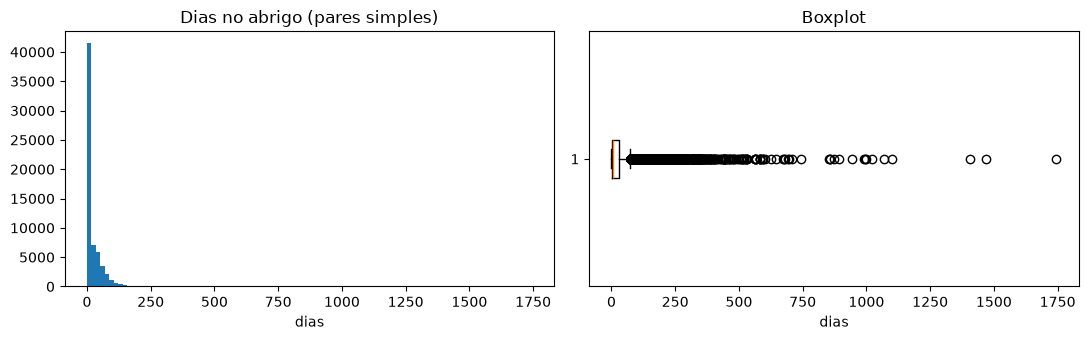

In [47]:
# histograma e boxplot lado a lado: a maioria sai rápido e poucos ficam muito
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(dias, bins=100)
ax[0].set_title("Dias no abrigo (pares simples)")
ax[0].set_xlabel("dias")
ax[1].boxplot(dias, orientation="horizontal")
ax[1].set_title("Boxplot")
ax[1].set_xlabel("dias")
plt.tight_layout()
plt.show()

In [48]:
# regra do IQR (1,5 x intervalo interquartil)
q1, q3 = dias.quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
print(f"Limite superior pelo IQR: {limite:.0f} dias")
print(f"Acima do limite: {(dias > limite).sum()} ({(dias > limite).mean():.1%})")
print("Acima de 1 ano:", (dias > 365).sum())
print("Máximo:", dias.max(), "dias")

Limite superior pelo IQR: 74 dias
Acima do limite: 4381 (6.9%)
Acima de 1 ano: 99
Máximo: 1745 dias


**Achados:**
- A distribuição dos dias no abrigo é **muito assimétrica**: a maioria sai em poucas semanas, mas há uma cauda longa.
- A regra do IQR marcaria quase 7% dos dados como outlier (tudo acima de ~74 dias). Isso acontece porque a distribuição é assimétrica por natureza: um gato ficar 3 meses não é erro.
- Os casos realmente extremos são poucos: cerca de 100 passam de 1 ano (menos de 0,2%) e o máximo chega perto de 5 anos. Não tenho como provar se são erro (ex.: uma saída e uma volta que não foram registradas) ou estadias reais.

### 3.13 Adoções com subtipo "Foster"

O `Outcome Subtype` detalha o desfecho. Nas adoções, um subtipo aparece muito: **Foster** (lar temporário). Comparo o tempo entre entrada e saída por subtipo, usando os mesmos pares simples.

In [49]:
# tempo das adoções por subtipo (o Foster inclui os dias em lar temporário)
adocoes = simples.assign(dias=dias)[simples["Outcome Type"] == "Adoption"]
adocoes.groupby(adocoes["Outcome Subtype"].fillna("(vazio)"))["dias"].agg(["count", "median"])

,count,median
Outcome Subtype,,
(vazio),21770,14.0
Barn,3,7.0
Foster,9406,55.0
Offsite,115,39.0


**Achado:** cerca de 30% das adoções têm subtipo `Foster`, e o tempo entre entrada e saída delas é bem maior que o das adoções sem subtipo. O portal não explica o subtipo, mas o nome sugere que o gato passou um tempo num **lar temporário** antes da adoção ser registrada. Se for isso, o tempo "no abrigo" dessas passagens inclui tempo fora do abrigo.

Não é um erro que dê pra corrigir, porque não sei quanto tempo o gato ficou em lar temporário. Mas é uma **limitação importante** para as perguntas sobre tempo até a adoção: o subtipo precisa continuar no dataset para o RA2 poder separar ou comparar esses casos.

### 3.14 Data de nascimento depois da saída

In [50]:
# nascimento depois da própria saída (os 12)
dob = pd.to_datetime(saidas["Date of Birth"])
print("Nascimento depois da saída:", (dob > sai_dt.dt.normalize()).sum())

Nascimento depois da saída: 12


**Achado:** alguns registros têm data de nascimento posterior à saída (impossível). Como `Date of Birth` só serve aqui para conferir a idade, isso **não afeta** o dataset final.

## 4. Resumo dos problemas encontrados

| # | Problema | Onde | Encontrado? | Tratamento (notebook 02) |
|---|---|---|---|---|
| 1 | Base com todos os animais | ambas | sim | filtrar `Animal Type == "Cat"` |
| 2 | Duplicados exatos | ambas | sim, poucos | remover |
| 3 | Mesma entrada registrada 2x (mesmo ID e hora) | entradas | sim, poucos | manter só a primeira |
| 4 | Mesmo gato com várias passagens | ambas | sim, cerca de 4% dos gatos | parear cada entrada com sua saída pelas datas |
| 5 | Entradas sem saída / saídas sem entrada | ambas | sim | entradas sem saída **ficam** marcadas como `sem_saida` (removê-las criaria viés nos anos recentes); saídas sem entrada ficam de fora |
| 6 | Datas como texto, em formatos diferentes, com fuso em parte das linhas | ambas | sim | converter para data |
| 7 | Horário da saída antes da entrada (mesmo dia) | saídas | sim | trabalhar com a **data** e aceitar saída no mesmo dia |
| 8 | Idade em texto, singular/plural misturado | ambas | sim | converter para meses |
| 9 | Idade negativa | ambas | sim, 1 gato | tratar como ausente |
| 10 | "0 years" (às vezes com nascimento poucos dias depois da entrada) | ambas | sim | manter como 0 (recém-nascido ou de poucos dias, confirmado pela data de nascimento e pela idade na saída) |
| 11 | Nome ausente / com `*` / peso, ID ou número no lugar do nome | ambas | sim | criar `tem_nome` e `nome_com_asterisco` |
| 12 | Sexo e castração na mesma coluna | ambas | sim | separar em `sexo` e `castrado` |
| 13 | Condição de entrada com categorias raras e que mudam com o tempo | entradas | sim | padronizar e agrupar as raras |
| 14 | Desfecho ausente e categorias não documentadas | saídas | sim | ausente vira "desconhecido"; `Rto-Adopt` fica separado da adoção (a prefeitura soma com devolução ao dono); `Disposal` fica sem tradução |
| 15 | Cores e raças com centenas de combinações raras | ambas | sim | cor principal, `is_black`, raça principal e agrupamento das raras |
| 16 | Maiúsculas/minúsculas inconsistentes | ambas | **não** | nada a fazer |
| 17 | Raça/cor/sexo diferentes entre as bases | ambas | **não** | nada a fazer |
| 18 | Tempo no abrigo muito longo | junção | sim, poucos casos | manter e sinalizar com uma flag |
| 19 | Idade muito alta (até 22 anos) | ambas | possível, não é erro | manter |
| 20 | Data de nascimento depois da saída | saídas | sim | coluna não entra no dataset final |
| 21 | `MonthYear` redundante e em formato diferente | ambas | sim | descartar |
| 22 | Adoções "Foster": o tempo pode incluir lar temporário | saídas | sim, ~30% das adoções | manter `subtipo_desfecho` no dataset e registrar a limitação para o RA2 |
| 23 | `Nursing` mistura filhote que mama e mãe que amamenta | entradas | sim | manter a categoria sem tradução; a idade separa os dois casos |
| 24 | Bases congeladas em 05/05/2025 | ambas | sim | registrar; explica as entradas sem saída (item 5) |